In [1]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:6 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:9 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,054 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,546 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/mai

In [2]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [3]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [4]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Writing setup.sh


In [5]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
# !cp /content/drive/MyDrive/Colab_CPP_OpenCV/* /content/
# !bash setup.sh

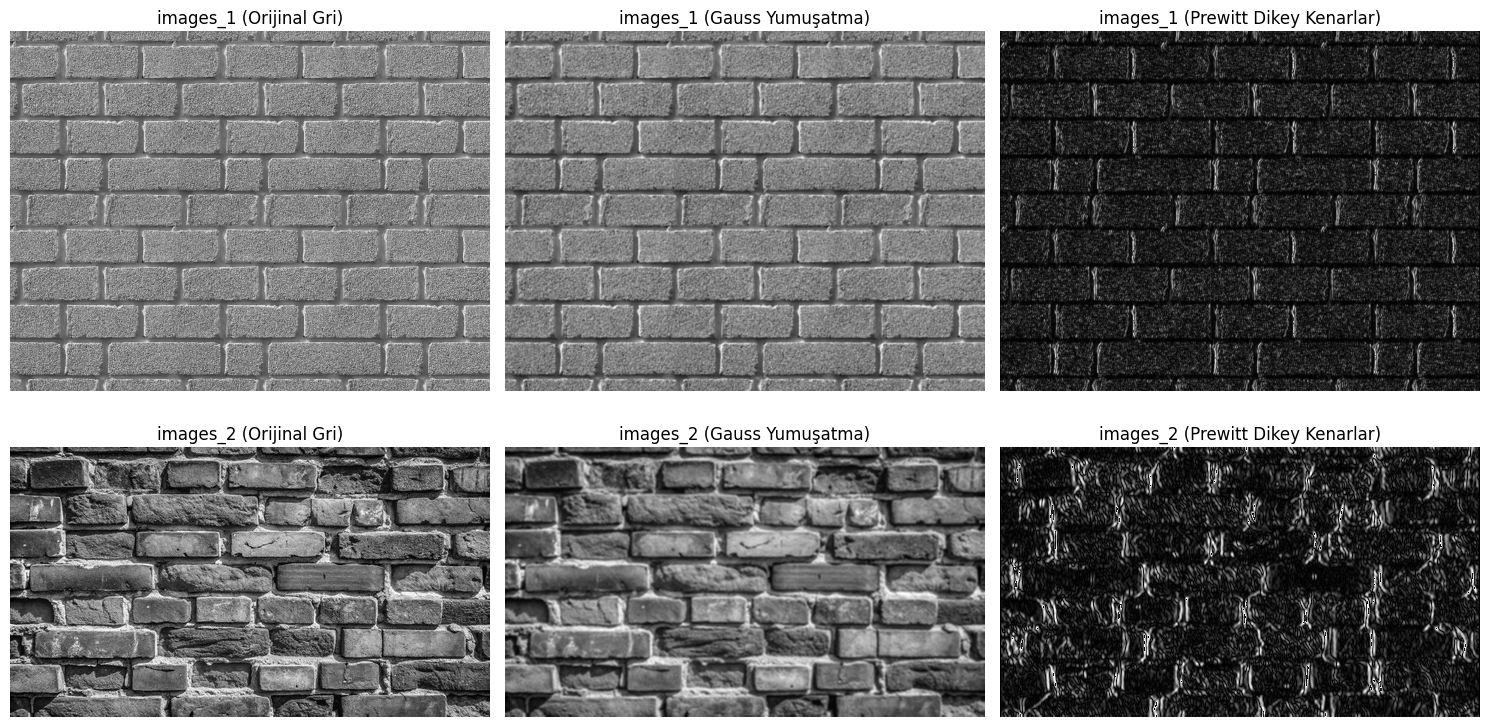

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def prewitt_filtresi_uygula(resim_yolu):
    # 1. Görüntüyü gri tonlamalı (grayscale) olarak yükle
    img = cv2.imread(resim_yolu, cv2.IMREAD_GRAYSCALE)

    # 2. Gürültüyü azaltmak için Gauss filtresi ile hafif yumuşat
    # (3x3 çekirdek boyutu ve sigmaX=1.0)
    blurred = cv2.GaussianBlur(img, (3, 3), sigmaX=1.0)

    # 3. İstenen 3x3 Prewitt dikey çekirdeği (vertical kernel)
    # [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]
    prewitt_kernel = np.array([
        [-1,  0,  1],
        [-1,  0,  1],
        [-1,  0,  1]
    ], dtype=np.float32)

    # 4. Konvolüsyon (negatif türevleri kaybetmemek için cv2.CV_64F kullanılır)
    edges = cv2.filter2D(blurred, cv2.CV_64F, prewitt_kernel)

    # 5. Mutlak değerini al ve 8-bit formatına dönüştür
    edges = np.uint8(np.absolute(edges))

    return img, blurred, edges

# Görselleri işle
img1, blur1, edge1 = prewitt_filtresi_uygula('images_1.jpeg')
img2, blur2, edge2 = prewitt_filtresi_uygula('images_2.jpeg')

# Sonuçları yan yana görselleştirme
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# images_1 sonuçları
axes[0, 0].imshow(img1, cmap='gray')
axes[0, 0].set_title('images_1 (Orijinal Gri)')
axes[0, 0].axis('off')

axes[0, 1].imshow(blur1, cmap='gray')
axes[0, 1].set_title('images_1 (Gauss Yumuşatma)')
axes[0, 1].axis('off')

axes[0, 2].imshow(edge1, cmap='gray')
axes[0, 2].set_title('images_1 (Prewitt Dikey Kenarlar)')
axes[0, 2].axis('off')

# images_2 sonuçları
axes[1, 0].imshow(img2, cmap='gray')
axes[1, 0].set_title('images_2 (Orijinal Gri)')
axes[1, 0].axis('off')

axes[1, 1].imshow(blur2, cmap='gray')
axes[1, 1].set_title('images_2 (Gauss Yumuşatma)')
axes[1, 1].axis('off')

axes[1, 2].imshow(edge2, cmap='gray')
axes[1, 2].set_title('images_2 (Prewitt Dikey Kenarlar)')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()